# Clustering

### **CAKE** (**C**onfidence in **A**ssignments via **K**-partition **E**nsembles)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.metrics import silhouette_samples, confusion_matrix
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import LabelEncoder

def sil_samples(X, labels, approximation=False, centers=None):
    """
    Compute silhouette scores for each point in the dataset,
    with approximate fast centroid-based computation option.
    """
    # Ensure arrays
    X = np.asarray(X)
    labels = np.asarray(labels)
    if X.ndim != 2:
       raise ValueError("X must be a 2D array of shape (n_samples, n_features).")
    if labels.ndim != 1 or labels.shape[0] != X.shape[0]:
       raise ValueError("labels must be a 1D array of length n_samples.")

    unique_labels, inv = np.unique(labels, return_inverse=True)
    k = unique_labels.size
    if k < 2:
       raise ValueError("Silhouette computation requires at least 2 clusters.")

    # Exact silhouette scores
    if approximation == False:
       silhouette_scores = silhouette_samples(X, labels=labels)
       return silhouette_scores

    # Centroid-based approximate silhouette scores
    n_samples, n_features = X.shape

    if centers is None:
       centers = np.array([X[inv == i].mean(axis=0) for i in range(k)], dtype=float)
    else:
       centers = np.asarray(centers, dtype=float)
       if centers.ndim != 2 or centers.shape[1] != n_features:
          raise ValueError(f"centers must have shape (k, d) with d={n_features}.")
       if centers.shape[0] != k:
          raise ValueError(f"centers.shape[0] must equal number of clusters k={k}.")
       if not np.array_equal(unique_labels, np.arange(k)):
          raise ValueError("When passing ndarray centers, labels must be dense 0..k-1.")

    # Squared distances to all centroids
    D_sq = euclidean_distances(X, centers, squared=True)

    # a(i): distance to own centroid
    a = np.sqrt(np.maximum(D_sq[np.arange(n_samples), inv], 0.0))

    # b(i): distance to nearest other centroid
    D_sq[np.arange(n_samples), inv] = np.inf
    b = np.sqrt(np.min(D_sq, axis=1))

    # Silhouette per point
    denom = np.maximum(np.maximum(a, b), 1e-12)
    s_point = (b - a) / denom

    # Singleton clusters -> silhouette = 0
    counts = np.bincount(inv, minlength=k).astype(int)
    s_point[counts[inv] < 2] = 0.0

    silhouette_scores = np.clip(s_point, -1.0, 1.0)

    return silhouette_scores

def sil_samples_stats(X, labels_list, approximation=False, centers_list=None):
    """
    Compute and aggregate silhouette scores across multiple clustering runs,
    returning per-sample mean and standard deviation of silhouette scores.
    """
    X = np.asarray(X)
    n_samples = X.shape[0]
    n_runs = len(labels_list)
    if n_runs < 2:
       raise ValueError("Clustering Ensemble must contain at least 2 partitions.")

    if centers_list is not None and len(centers_list) != n_runs:
       raise ValueError("centers_list must match the number of labelings in labels_list")

    # Initialize matrix to hold silhouette scores
    sil_scores = np.zeros((n_runs, n_samples), dtype=float)

    for i, labels in enumerate(labels_list):
        labels_arr = np.asarray(labels)
        centers = None
        if approximation and centers_list is not None:
           centers = centers_list[i]

        # Compute silhouette scores for this run
        sil_scores[i] = sil_samples(X, labels_arr, approximation=approximation, centers=centers)

    # Compute mean and standard deviation of sample-silhouette scores over the ensemble
    mean_sil_samples = sil_scores.mean(axis=0)
    std_sil_samples = sil_scores.std(axis=0)

    return mean_sil_samples, std_sil_samples

def align_labels(target, source):
    """
    Aligns the labels in "source" to match the labels in "target"
    using the Hungarian Algorithm based on a contingency matrix.

    Parameters:
    - target: array-like of shape (n_samples,)
              The reference label vector to align to.
    - source: array-like of shape (n_samples,)
              The label vector to be permuted for alignment.

    Returns:
    - aligned: np.ndarray of shape (n_samples,)
               The source labels, remapped to best match the target labels.
    """
    target = np.asarray(target)
    source = np.asarray(source)
    unique_target = np.unique(target)
    unique_source = np.unique(source)
    if len(unique_target) != len(unique_source):
       raise ValueError(
           f"Cannot align: Target has {len(unique_target)} clusters {unique_target.tolist()}, "
           f"but source has {len(unique_source)} clusters {unique_source.tolist()}"
       )
    # Encode labels to indices based on their unique values
    le_target = LabelEncoder().fit(unique_target)
    le_source = LabelEncoder().fit(unique_source)

    target_encoded = le_target.transform(target)
    source_encoded = le_source.transform(source)

    # Confusion matrix with indices aligned to encoded labels
    c_matrix = confusion_matrix(target_encoded, source_encoded)

    # Apply the Hungarian algorithm
    row_ind, col_ind = linear_sum_assignment(-c_matrix)

    # Create mapping from source labels to target labels
    mapping = {
        le_source.classes_[src_col]: le_target.classes_[tgt_row]
        for tgt_row, src_col in zip(row_ind, col_ind)
    }
    # Remap source labels using the mapping
    aligned = np.vectorize(mapping.get)(source)

    return aligned

def pairwise_stability(labels_runs):
    """
    Computes per-point clustering stability across multiple runs by aligning labels
    pairwise using the Hungarian algorithm to account for label permutations.

    Parameters:
    - labels_runs: list of array-like
        List of label arrays from multiple clustering runs. Each array must have the
        same number of samples and clusters (unique labels).

    Returns:
    - stability: np.ndarray of shape (n_samples,)
        Per-point stability score between 0 and 1, indicating the fraction of run-pairs
        where the point's label matches after optimal alignment.

    Notes:
    - Requires all runs to have the same number of clusters (unique labels).
    - Label alignment is done pairwise between runs using the Hungarian algorithm.
    - High stability (~1) indicates stable cluster assignments across runs.
    """
    labels_runs = [np.asarray(labels) for labels in labels_runs]
    n_runs, n_samples = len(labels_runs), len(labels_runs[0])
    if n_runs < 2:
       raise ValueError("pairwise_stability needs at least 2 runs.")

    # Counters: How many run-pairs agree per point
    agreement_counts = np.zeros(n_samples, dtype=int)
    total_pairs = 0

    # For every unique pair of runs
    for r1 in range(n_runs):
        labels_r1 = labels_runs[r1]
        for r2 in range(r1+1, n_runs):
            labels_r2 = labels_runs[r2]

            # Align labels_r2 to labels_r1 using Hungarian
            aligned_r2 = align_labels(labels_r1, labels_r2)
            matches = (labels_r1 == aligned_r2)

            # Add matches to total per-point agreement count
            agreement_counts += matches
            total_pairs += 1

    return agreement_counts/total_pairs

def cake(X, labels_list, method='product', approximation=False, centers_list=None, geom_norm='clip'):
    """
    Compute a confidence score per point for clustering ensembles, defined as:
    stability_i * geometric_stability_i or
    2 * stability_i * geometric_stability_i / [stability_i + geometric_stability_i]
    where stability is the pairwise label agreement across runs,
    and mean_sil_i, std_sil_i are the statistics from sil_samples_stats.

    Parameters:
    - X: array-like, shape (n_samples, n_features)
    - labels_list: list of array-like, each of shape (n_samples,)
        A list of cluster labelings for the same dataset X.
    - approximation: bool, default=False
        Whether to use the approximate silhouette computation.
    - centers_list: list of pd.Series or array-like, optional
        If approximation=True, an optional list of centroids for each clustering.
    - method: str, default='product'
        'product' or 'harmonic_mean' for the formulation of the CAKE scores.
    - geo_norm: str, default='clip'
        - 'affine' (default): maps geom_raw in [-1,1] to [0,1] via (x+1)/2 (preserves negatives).
        - 'clip': max(mean_sil - std_sil, 0) clipped at 1 (original behavior; discards negatives).

    Returns:
    - cake_scores: np.ndarray, shape (n_samples,)
        The CAKE scores for each point.
    - stability: np.ndarray, shape (n_samples,)
        The stability scores for each point.
    - geom_stability: np.ndarray, shape (n_samples,)
        The silhouette-based reliability scores for each point (mean_sil_i - std_sil_i).
    - summary: pd.DataFrame
        Summary of above metrics per point in X.
    """
    # Compute silhouette statistics
    mean_sil, std_sil = sil_samples_stats(X, labels_list,
                                          approximation=approximation,
                                          centers_list=centers_list)

    # Assignment stability across the ensemble
    stability = pairwise_stability(labels_list)

    # Silhouette-based stability across the ensemble
    geom_raw = mean_sil - std_sil
    if geom_norm == 'clip':
       geom_stability = np.clip(mean_sil - std_sil, 0.0, 1.0)
    else:
       geom_stability = np.clip((geom_raw + 1) / 2, 0, 1) # preserves information for negative scores

    # Calculate confidence scores
    if method == 'product':
       cake_scores = stability * geom_stability
    elif method == 'harmonic_mean':
       num = 2.0 * stability * geom_stability
       denom = np.maximum(stability + geom_stability, 1e-8)
       cake_scores = num / denom
    else:
       raise ValueError(
           f"Unknown method: {method}. Use 'product' or 'harmonic_mean'."
       )

    # Summary DataFrame
    summary = pd.DataFrame({
        'Mean Silhouette': mean_sil,
        'STD Silhouette': std_sil,
        'Geometric Stability': geom_stability,
        'Assignment Stability': stability,
        'CAKE': cake_scores
    })

    return cake_scores, stability, geom_stability, summary

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from collections import OrderedDict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, Normalize

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    silhouette_samples,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from scipy.stats import spearmanr
from scipy.stats import t
from sklearn.metrics import f1_score, adjusted_mutual_info_score
from scipy.stats import kendalltau, spearmanr
from sklearn.mixture import GaussianMixture
from sklearn.metrics import average_precision_score, roc_auc_score

from sklearn.decomposition import PCA
from collections import Counter
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import NearestNeighbors
import time, gc

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    accuracy = cm[row_ind, col_ind].sum() / np.sum(cm)
    return accuracy

def micro_sil(X, labels, approximation=False, centers=None):
    s = sil_samples(X, labels, approximation=approximation, centers=centers)
    return float(np.mean(s))

def macro_sil(X, labels, approximation=False, centers=None):
    labels = np.asarray(labels)
    s = sil_samples(X, labels, approximation=approximation, centers=centers)
    uniq = np.unique(labels)
    cluster_means = [s[labels == lab].mean() for lab in uniq]
    return float(np.mean(cluster_means))

def consensus_medoid_majority(labels_runs):
    if not labels_runs:
        raise ValueError("labels_runs must be a non-empty list of 1D arrays.")
    labs = [np.asarray(l) for l in labels_runs]
    R = len(labs)
    n = labs[0].shape[0]
    if any(len(l) != n for l in labs):
        raise ValueError("All runs must have the same number of samples.")

    ks = {np.unique(l).size for l in labs}
    if len(ks) != 1:
        raise ValueError(f"All runs must have the same number of clusters; got {sorted(ks)}.")

    # pairwise symmetric Hamming distances after alignment
    D = np.zeros((R, R), dtype=float)
    for i in range(R):
        li = labs[i]
        for j in range(i+1, R):
            lj = labs[j]
            aligned_j = align_labels(li, lj)
            d_ij = 1.0 - np.mean(aligned_j == li)
            aligned_i = align_labels(lj, li)
            d_ji = 1.0 - np.mean(aligned_i == lj)
            D[i, j] = D[j, i] = 0.5 * (d_ij + d_ji)

    medoid = int(np.argmin(D.sum(axis=1)))
    ref = labs[medoid]
    aligned = [align_labels(ref, l) for l in labs]   # align all runs to the medoid
    A = np.vstack(aligned)                           # (R, n)

    # majority vote per point; tie -> medoid label
    z_star = np.empty(n, dtype=ref.dtype)
    for i in range(n):
        counts = Counter(A[:, i])
        top = counts.most_common(2)
        if len(top) == 1 or top[0][1] > top[1][1]:
            z_star[i] = top[0][0]
        else:
            z_star[i] = ref[i]  # tie-break to medoid label

    agree = np.mean(A == z_star, axis=0)
    return z_star, agree

### Data: Normalization, PCA, and $k$ Selection

**Embeddings**

In [ ]:

import numpy as np
import os

file_name = 'par_embeddings.npy'

path = f'./out_files/{file_name}'

if os.path.exists(path):
    X = np.load(path)
    print("loaded")
    print(f"\nEmbeddings (Samples, Dimensions): {X.shape}")
else:
    print(f"File not found: {path}")

loaded

Embeddings (Samples, Dimensions): (117716, 4096)


**Paragraphs**

In [ ]:
import pandas as pd
import os

base_path = 'C:/Users/thomt/Desktop/setn/paragraphs/out_files'
file_name_sp = '01_paragraphs_clean.csv'
path_sp = os.path.join(base_path, file_name_sp)

if os.path.exists(path_sp):
    df = pd.read_csv(path_sp)
    print(f"Shape: {df.shape}")
    display(df.head(3))
else:
    print(f"File not found: {path_sp}")

Shape: (117716, 8)


,member_name,party,sitting_date,member_gender,speech_id,paragraph_id,paragraph,par_clean
0,κελετσης δημητριου σταυρος,Nea Dimokratia,2023-03,male,2023-03-07_1_4,2023-03-07_1_4_p1,"Ευχαριστώ, κύριε Πρόεδρε. Κύριε Πρόεδρε, εκφρά...",ευχαριστω κυριε προεδρε κυριε προεδρε εκφραζω ...
1,κελετσης δημητριου σταυρος,Nea Dimokratia,2023-03,male,2023-03-07_1_4,2023-03-07_1_4_p2,"Απέναντι σε αυτά τα παιδιά, τα θύματα αυτής τη...",απεναντι σε αυτα τα παιδια τα θυματα αυτης της...
2,κελετσης δημητριου σταυρος,Nea Dimokratia,2023-03,male,2023-03-07_1_4,2023-03-07_1_4_p3,"Κυρίες και κύριοι συνάδελφοι, εισερχόμενος στη...",κυριες και κυριοι συναδελφοι εισερχομενος στη ...


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Scale the data (just like before)
X_scaled = StandardScaler().fit_transform(X)

# 2. Fit PCA with exactly 100 components
pca_100 = PCA(n_components=100, random_state=42)
pca_100.fit(X_scaled) # We only need to fit it to check the variance

# 3. Calculate the cumulative explained variance
explained_100 = pca_100.explained_variance_ratio_.cumsum()

# 4. Grab the final value (which represents the total variance for all 100 components)
total_variance_100 = explained_100[-1]

print(f"Total variance explained by 100 components: {total_variance_100:.4f} ({total_variance_100 * 100:.2f}%)")

Total variance explained by 100 components: 0.5672 (56.72%)


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=100, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"New shape: {X_pca.shape}")

New shape: (117716, 100)


### Micro- and Macro-averaged Silhouette Scores

Starting K-selection tests (with centroid approximation)...
k=15 | Micro-Sil: 0.0884 | Macro-Sil: 0.0950
k=16 | Micro-Sil: 0.0868 | Macro-Sil: 0.0924
k=17 | Micro-Sil: 0.0897 | Macro-Sil: 0.0953
k=18 | Micro-Sil: 0.0901 | Macro-Sil: 0.0960
k=19 | Micro-Sil: 0.0898 | Macro-Sil: 0.0945
k=20 | Micro-Sil: 0.0912 | Macro-Sil: 0.0954
k=21 | Micro-Sil: 0.0874 | Macro-Sil: 0.0998
k=22 | Micro-Sil: 0.0925 | Macro-Sil: 0.1024
k=23 | Micro-Sil: 0.0908 | Macro-Sil: 0.1014
k=24 | Micro-Sil: 0.0903 | Macro-Sil: 0.0985
k=25 | Micro-Sil: 0.0876 | Macro-Sil: 0.0961
k=26 | Micro-Sil: 0.0882 | Macro-Sil: 0.0957
k=27 | Micro-Sil: 0.0927 | Macro-Sil: 0.1011
k=28 | Micro-Sil: 0.0955 | Macro-Sil: 0.1029
k=29 | Micro-Sil: 0.0935 | Macro-Sil: 0.1024
k=30 | Micro-Sil: 0.0907 | Macro-Sil: 0.0997
k=31 | Micro-Sil: 0.0951 | Macro-Sil: 0.0998
k=32 | Micro-Sil: 0.0909 | Macro-Sil: 0.0994
k=33 | Micro-Sil: 0.0897 | Macro-Sil: 0.0949
k=34 | Micro-Sil: 0.0911 | Macro-Sil: 0.0979
k=35 | Micro-Sil: 0.0923 | Macro-Sil: 0.

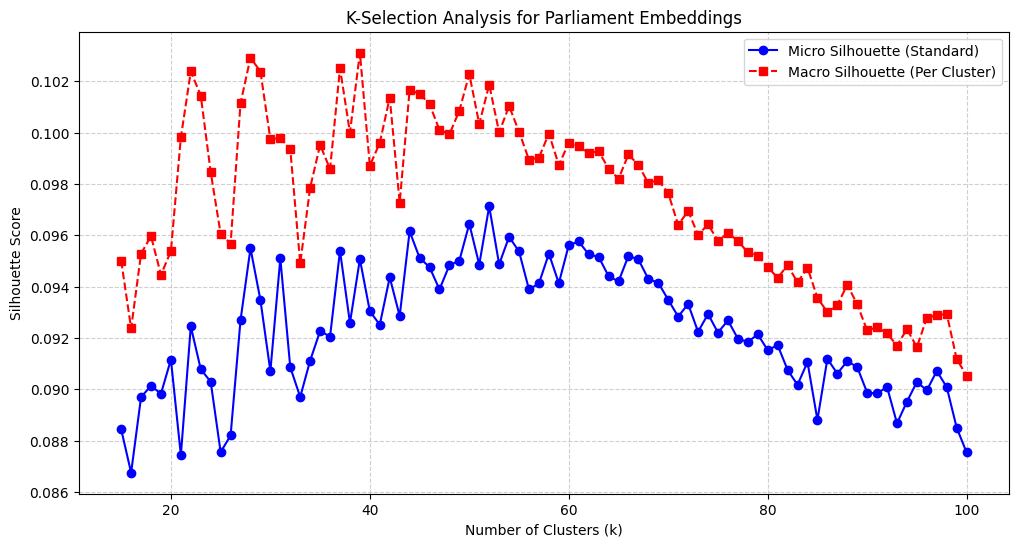

In [ ]:
import matplotlib.pyplot as plt

kmin, kmax, step = 15, 101, 1

k_range = range(kmin, kmax, step)
micro_scores = []
macro_scores = []

print("Starting K-selection tests (with centroid approximation)...")

for k_test in k_range:
    km_test = KMeans(n_clusters=k_test, random_state=42, n_init=3)
    labels_test = km_test.fit_predict(X_pca)
    centroids_test = km_test.cluster_centers_

    mi_s = micro_sil(X_pca, labels_test, approximation=True, centers=centroids_test)
    ma_s = macro_sil(X_pca, labels_test, approximation=True, centers=centroids_test)

    micro_scores.append(mi_s)
    macro_scores.append(ma_s)

    print(f"k={k_test} | Micro-Sil: {mi_s:.4f} | Macro-Sil: {ma_s:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(k_range, micro_scores, 'o-', label='Micro Silhouette (Standard)', color='blue')
plt.plot(k_range, macro_scores, 's--', label='Macro Silhouette (Per Cluster)', color='red')

plt.title('K-Selection Analysis for Parliament Embeddings')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

--- Final K-Selection Results ---

Best K (Micro-Sil):    52  (Score: 0.0971)
Best K (Macro-Sil):    39  (Score: 0.1031)
Best K (Harmonic):     52  (Score: 0.0994)


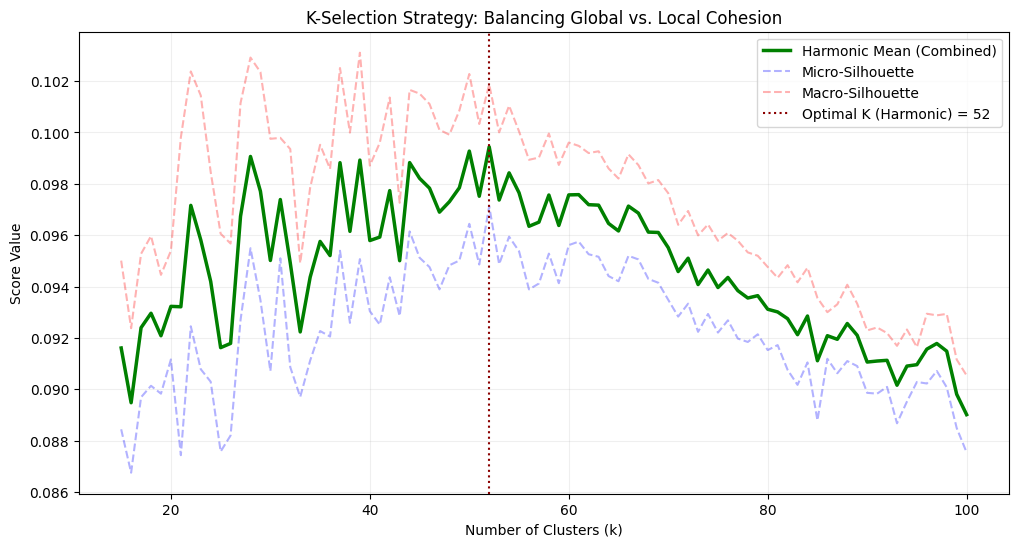

In [ ]:
micro_np = np.array(micro_scores)
macro_np = np.array(macro_scores)

harmonic_mean_scores = 2 * (micro_np * macro_np) / (micro_np + macro_np + 1e-9)

idx_micro = np.argmax(micro_np)
idx_macro = np.argmax(macro_np)
idx_harmonic = np.argmax(harmonic_mean_scores)

best_k_micro = k_range[idx_micro]
best_k_macro = k_range[idx_macro]
best_k_harmonic = k_range[idx_harmonic]

print(f"--- Final K-Selection Results ---\n")
print(f"Best K (Micro-Sil):    {best_k_micro}  (Score: {micro_np[idx_micro]:.4f})")
print(f"Best K (Macro-Sil):    {best_k_macro}  (Score: {macro_np[idx_macro]:.4f})")
print(f"Best K (Harmonic):     {best_k_harmonic}  (Score: {harmonic_mean_scores[idx_harmonic]:.4f})")

plt.figure(figsize=(12, 6))
plt.plot(k_range, harmonic_mean_scores, 'g-', label='Harmonic Mean (Combined)', linewidth=2.5)

plt.plot(k_range, micro_np, 'b--', alpha=0.3, label='Micro-Silhouette')
plt.plot(k_range, macro_np, 'r--', alpha=0.3, label='Macro-Silhouette')

plt.axvline(x=best_k_harmonic, color='darkred', linestyle=':',
            label=f'Optimal K (Harmonic) = {best_k_harmonic}')

plt.title('K-Selection Strategy: Balancing Global vs. Local Cohesion')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Score Value')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

### Clustering Ensemble and CAKE Scores

In [ ]:
from sklearn.cluster import KMeans

k_final = best_k_harmonic
n_runs = 10
labels_list = []
centers_list = []

print(f"Running CAKE Ensemble for k={k_final}...")

for i in range(n_runs):

    km = KMeans(n_clusters=k_final, random_state=i, n_init=3)
    labels = km.fit_predict(X_pca)

    labels_list.append(labels)
    centers_list.append(km.cluster_centers_)

    if (i+1) % 2 == 0:
        print(f"Completed run {i+1}/{n_runs}")

print("Ensemble Construction: Finished")

cake_scores, stability, geom_stability, summary = cake(
    X_pca,
    labels_list,
    method='harmonic_mean',
    approximation=True,
    centers_list=centers_list,
    geom_norm='affine'
)

print("\nCAKE Scores Computed.\n")

Running CAKE Ensemble for k=52...
Completed run 2/10
Completed run 4/10
Completed run 6/10
Completed run 8/10
Completed run 10/10
Ensemble Construction: Finished

CAKE Scores Computed.



**Consensus clustering and CAKE summary**

In [ ]:
z_star, agreement = consensus_medoid_majority(labels_list)
summary['Final_Cluster'] = z_star
summary['Agreement_Rate'] = agreement

display(summary.head(5))

,Mean Silhouette,STD Silhouette,Geometric Stability,Assignment Stability,CAKE,Final_Cluster,Agreement_Rate
0,0.021349,0.024768,0.498290,0.266667,0.347411,28,0.4
1,0.108580,0.008270,0.550155,0.533333,0.541614,25,0.7
2,0.045427,0.004698,0.520364,0.800000,0.630571,47,0.9
3,0.201745,0.028341,0.586702,1.000000,0.739524,47,1.0
4,0.125931,0.022164,0.551884,1.000000,0.711244,47,1.0


### CAKE scores distribution

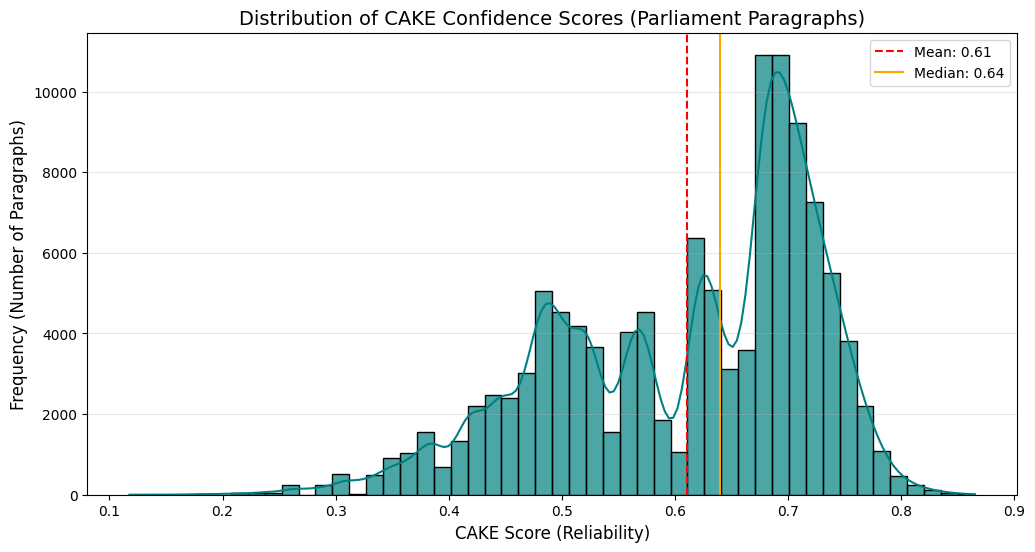

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.histplot(summary['CAKE'], bins=50, kde=True, color='teal', edgecolor='black', alpha=0.7)

plt.axvline(summary['CAKE'].mean(), color='red', linestyle='--', label=f"Mean: {summary['CAKE'].mean():.2f}")
plt.axvline(summary['CAKE'].median(), color='orange', linestyle='-', label=f"Median: {summary['CAKE'].median():.2f}")

plt.title('Distribution of CAKE Confidence Scores (Parliament Paragraphs)', fontsize=14)
plt.xlabel('CAKE Score (Reliability)', fontsize=12)
plt.ylabel('Frequency (Number of Paragraphs)', fontsize=12)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

### Consensus Clustering Analysis

In [ ]:
# Consensus clustering aggrement stats
mean_agreement = summary['Agreement_Rate'].mean()
median_agreement = summary['Agreement_Rate'].median()
std_agreement = summary['Agreement_Rate'].std()

# Docs wirh Agreement == 1.0
unanimous_ratio = (summary['Agreement_Rate'] == 1.0).mean() * 100

print(f"\n--- Consensus Ensemble Statistics (n_runs={n_runs}) ---")
print(f"Mean Agreement: {mean_agreement:.4f}")
print(f"Median Agreement: {median_agreement:.4f}")
print(f"Standard Deviation: {std_agreement:.4f}")
print(f"Unanimous Decisions: {unanimous_ratio:.2f}% of total speeches")

# Cluster sizes stats
cluster_counts = summary['Final_Cluster'].value_counts().sort_index()
print("\n--- Cluster Size Distribution ---")
display(cluster_counts.describe())


--- Consensus Ensemble Statistics (n_runs=10) ---
Mean Agreement: 0.8240
Median Agreement: 0.9000
Standard Deviation: 0.2057
Unanimous Decisions: 44.46% of total speeches

--- Cluster Size Distribution ---


count      52.000000
mean     2263.769231
std       838.566462
min       455.000000
25%      1600.750000
50%      2205.500000
75%      2782.000000
max      4169.000000
Name: count, dtype: float64

**Silhouette Scores on Consensus Partition**

In [ ]:
# Calculate silhouette scores for the final consensus labels (z_star)
#  approximation=True for speed given the 60k samples
consensus_sil_scores = sil_samples(X_pca, z_star, approximation=True)

# Add scores to summary df
summary['Consensus_Silhouette'] = consensus_sil_scores

display(summary.head(2))

,Mean Silhouette,STD Silhouette,Geometric Stability,Assignment Stability,CAKE,Final_Cluster,Agreement_Rate,Consensus_Silhouette
0,0.021349,0.024768,0.498290,0.266667,0.347411,28,0.4,0.004839
1,0.108580,0.008270,0.550155,0.533333,0.541614,25,0.7,0.122087


In [ ]:
# aggregate metrics per cluster using cluster labels
cluster_profiles = summary.groupby('Final_Cluster').agg(
    Size=('CAKE', 'count'),
    mean_CAKE=('CAKE', 'mean'),
    std_CAKE=('CAKE', 'std'),
    mean_Agreement=('Agreement_Rate', 'mean'),
    mean_Silhouette=('Consensus_Silhouette', 'mean') # Silhouette per cluster
).reset_index()

# percentage share of each cluster
cluster_profiles['share'] = (cluster_profiles['Size'] / len(summary)) * 100

# rename
cluster_profiles = cluster_profiles.rename(columns={'Final_Cluster': 'cluster_label'})

# cluster label as idx
final_report = cluster_profiles.set_index('cluster_label')

# reorder columns
final_report = final_report[['Size', 'share', 'mean_CAKE', 'std_CAKE', 'mean_Agreement', 'mean_Silhouette']]

# Calculate the Global Silhouette of the consensus partition
total_consensus_sil = consensus_sil_scores.mean()

print(f"Total Consensus Silhouette Score: {total_consensus_sil:.4f}")
print("\n--- Cluster Statistical Profiles (Consensus Partition) ---")

display(final_report)

Total Consensus Silhouette Score: 0.0912

--- Cluster Statistical Profiles (Consensus Partition) ---


,Size,share,mean_CAKE,std_CAKE,mean_Agreement,mean_Silhouette
cluster_label,,,,,,
0,1488,1.264059,0.472770,0.038017,0.587164,0.076657
1,1187,1.008359,0.726864,0.058052,0.985678,0.171965
2,1394,1.184206,0.703730,0.071163,0.971306,0.135200
3,3787,3.217065,0.549208,0.107960,0.756087,0.041131
4,1886,1.602161,0.671836,0.094643,0.933139,0.111951
5,3135,2.663189,0.499734,0.083134,0.528931,0.039921
6,2265,1.924122,0.496316,0.057287,0.661104,0.061130
7,2254,1.914778,0.581157,0.086429,0.801908,0.067280
8,1935,1.643787,0.644972,0.093813,0.892610,0.105309


C:\Users\thomt\AppData\Local\Temp\ipykernel_11256\2858390423.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=final_report.index, y='share', data=final_report, palette='magma', edgecolor='black')


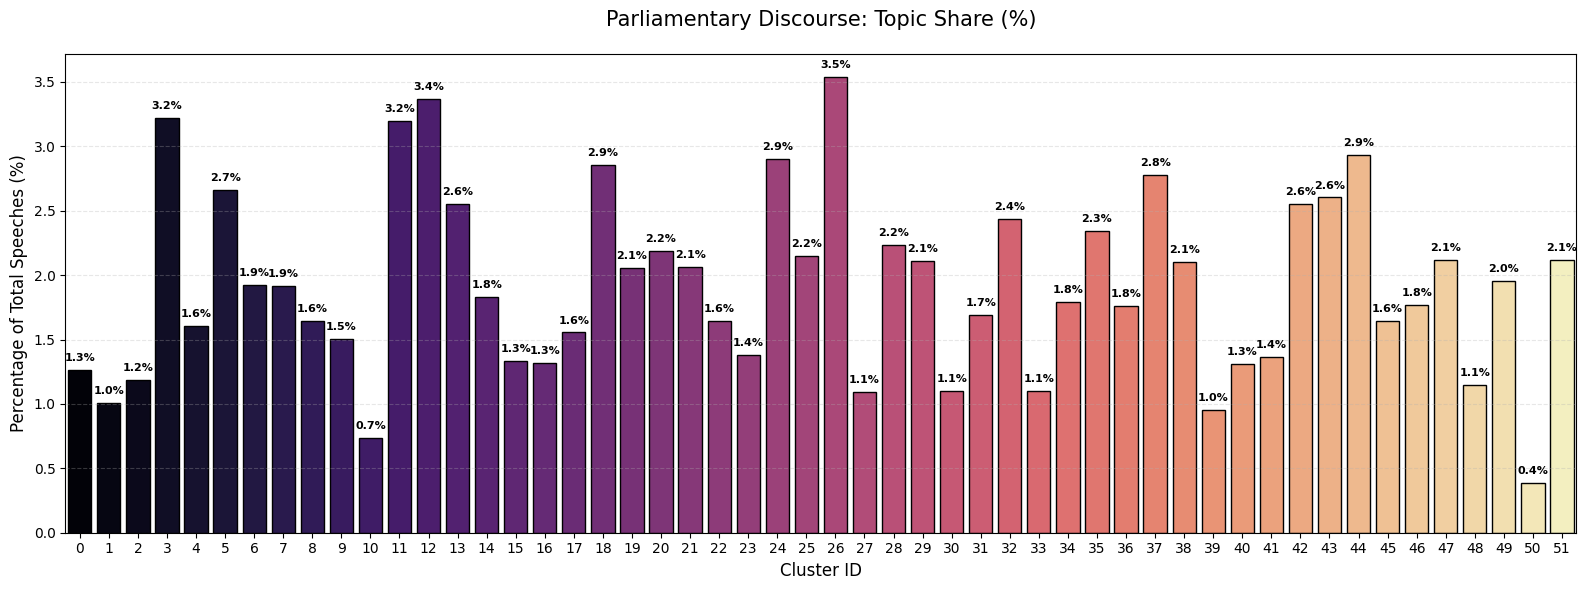

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 6))

ax = sns.barplot(x=final_report.index, y='share', data=final_report, palette='magma', edgecolor='black')

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=8, fontweight='bold', xytext=(0, 5),
                textcoords='offset points')

plt.title('Parliamentary Discourse: Topic Share (%)', fontsize=15, pad=20)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Percentage of Total Speeches (%)', fontsize=12)
plt.xticks(final_report.index)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\thomt\AppData\Local\Temp\ipykernel_11256\3670453047.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=final_report.index, y='mean_Silhouette', data=final_report, palette=colors, edgecolor='black')


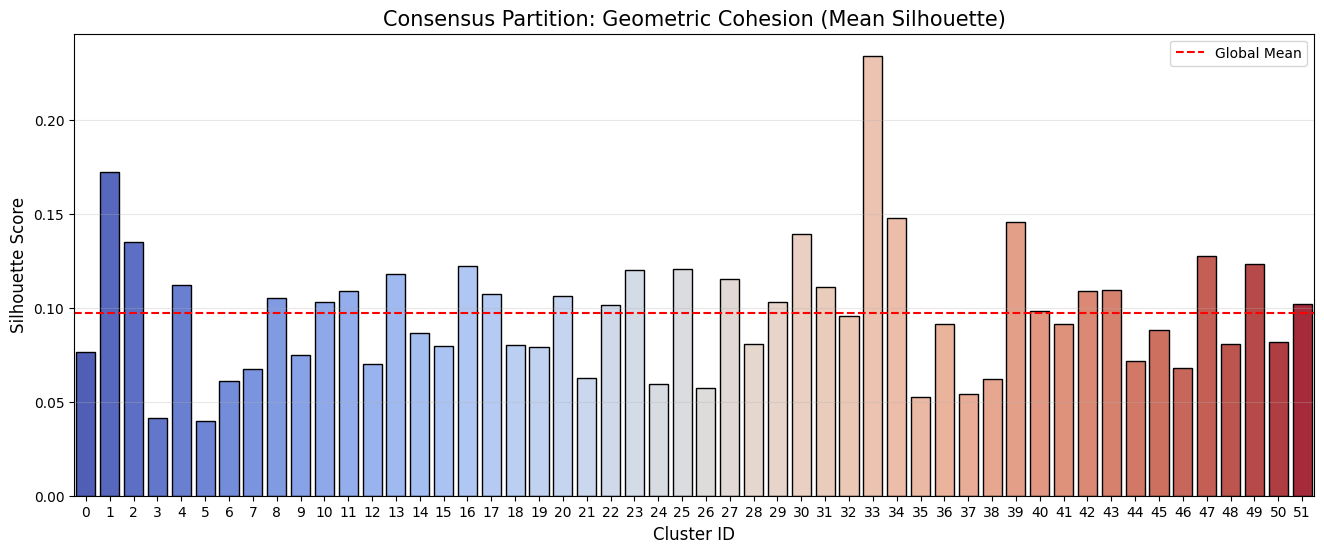

In [ ]:
plt.figure(figsize=(16, 6))
colors = sns.color_palette("coolwarm", len(final_report))
ax = sns.barplot(x=final_report.index, y='mean_Silhouette', data=final_report, palette=colors, edgecolor='black')

plt.axhline(y=final_report['mean_Silhouette'].mean(), color='red', linestyle='--', label='Global Mean')
plt.title('Consensus Partition: Geometric Cohesion (Mean Silhouette)', fontsize=15)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

In [ ]:
display(summary)

,Mean Silhouette,STD Silhouette,Geometric Stability,Assignment Stability,CAKE,Final_Cluster,Agreement_Rate,Consensus_Silhouette
0,0.021349,0.024768,0.498290,0.266667,0.347411,28,0.4,0.004839
1,0.108580,0.008270,0.550155,0.533333,0.541614,25,0.7,0.122087
2,0.045427,0.004698,0.520364,0.800000,0.630571,47,0.9,0.045500
3,0.201745,0.028341,0.586702,1.000000,0.739524,47,1.0,0.169909
4,0.125931,0.022164,0.551884,1.000000,0.711244,47,1.0,0.123288
...,...,...,...,...,...,...,...,...
117711,0.128364,0.067580,0.530392,1.000000,0.693145,51,1.0,0.069935
117712,0.065122,0.036411,0.514355,0.466667,0.489352,0,0.6,0.031970
117713,0.064361,0.026315,0.519023,0.466667,0.491454,0,0.6,0.076010
117714,0.021005,0.013671,0.503667,0.622222,0.556703,44,0.8,0.020993


### Filtering

--- Step 1: Denoising (CAKE >= 30th Percentile) ---
Cutoff Value: 0.5410
Samples remaining: 82401 (70.0% of original)

--- Step 2: Re-evaluating K for 70% Stable Subset ---


,Size,share,mean_CAKE,std_CAKE,mean_Agreement,mean_Silhouette
cluster_label,,,,,,
0,2867,3.479327,0.668374,0.044311,0.947367,0.103601
1,3593,4.360384,0.679567,0.054180,0.956220,0.076496
2,1625,1.972063,0.656287,0.046199,0.920615,0.110197
3,1742,2.114052,0.688925,0.055594,0.968255,0.121532
4,1434,1.740270,0.690651,0.054960,0.970293,0.120735
5,2141,2.598269,0.707626,0.051770,0.981924,0.152597
6,1626,1.973277,0.698982,0.051780,0.969557,0.090139
7,1708,2.072790,0.667800,0.071330,0.923653,0.201030
8,2569,3.117681,0.664143,0.052629,0.948307,0.086217


C:\Users\thomt\AppData\Local\Temp\ipykernel_11256\3829178850.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=final_report_stable.index, y='share', data=final_report_stable, palette='magma', edgecolor='black')


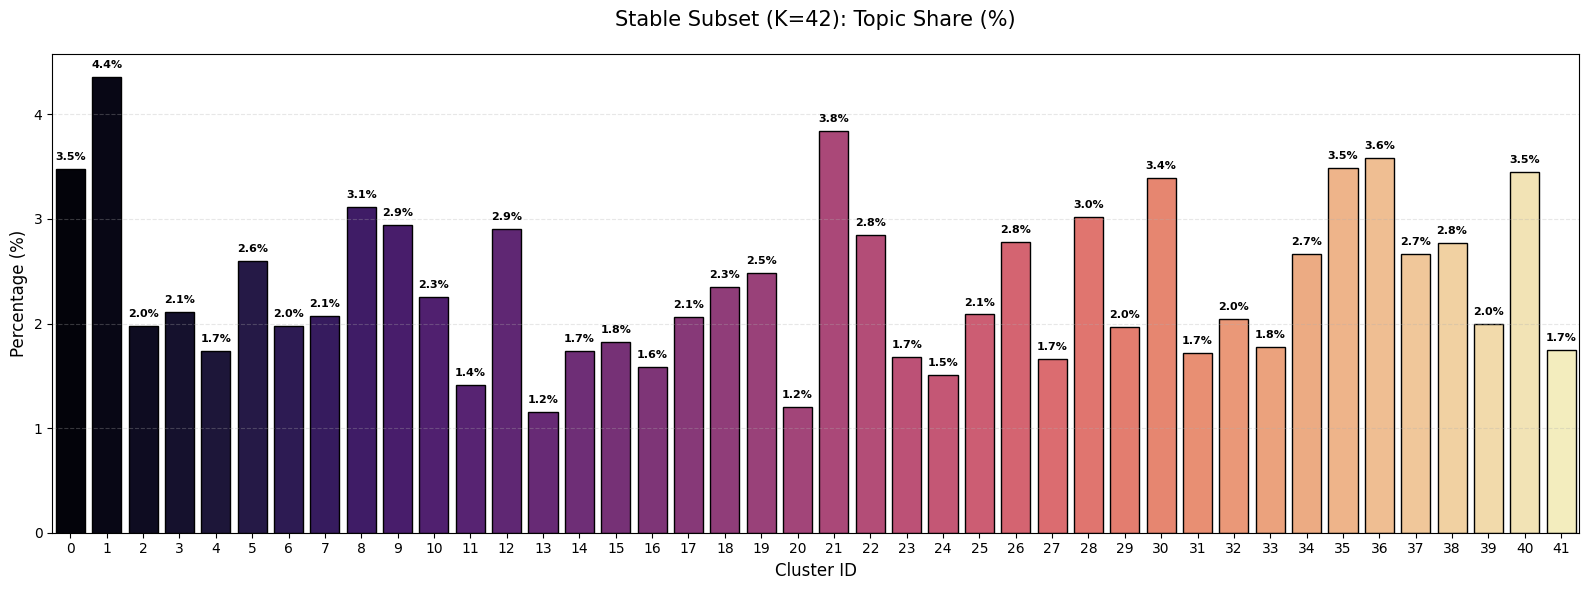

C:\Users\thomt\AppData\Local\Temp\ipykernel_11256\3829178850.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x=final_report_stable.index, y='mean_Silhouette', data=final_report_stable, palette=colors, edgecolor='black')


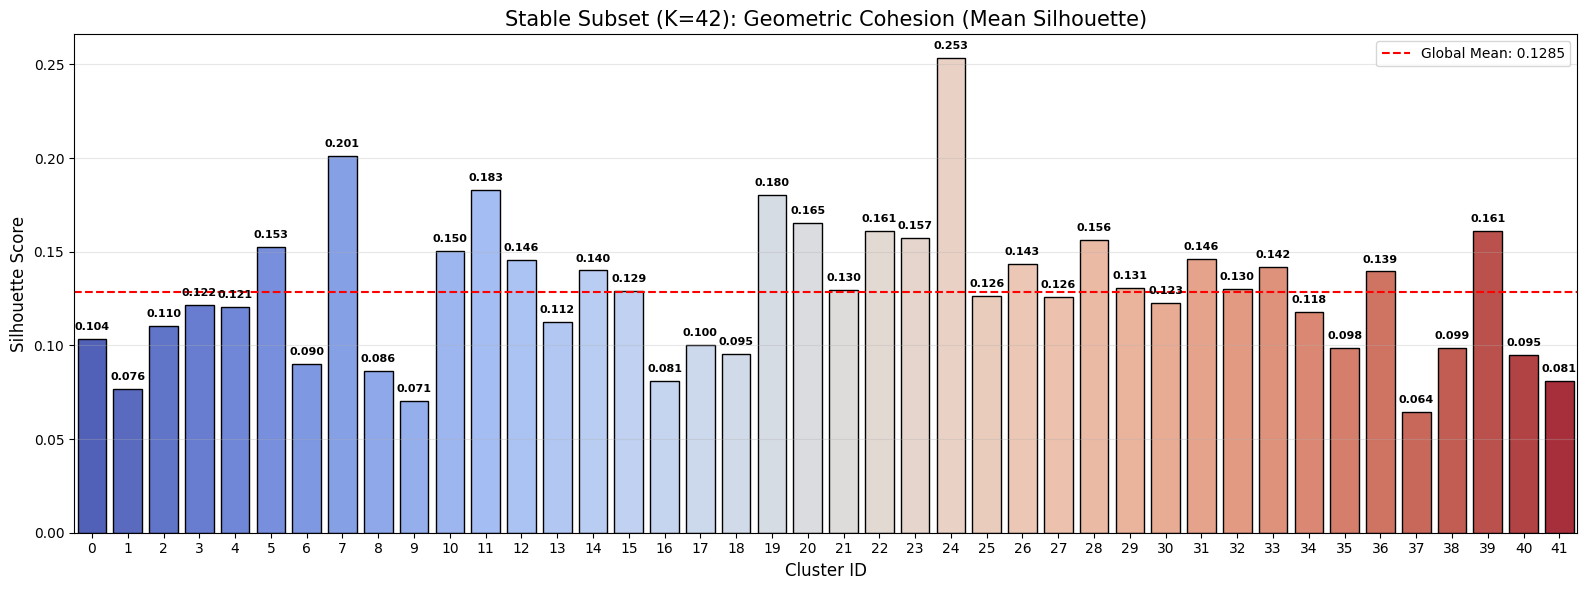

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

cutoff_30 = np.percentile(summary['CAKE'], 30)
stable_indices = np.where(summary['CAKE'] >= cutoff_30)[0]
X_stable = X_pca[stable_indices]
summary_stable = summary.iloc[stable_indices].copy()

print(f"--- Step 1: Denoising (CAKE >= 30th Percentile) ---")
print(f"Cutoff Value: {cutoff_30:.4f}")
print(f"Samples remaining: {len(X_stable)} ({len(X_stable)/len(X_pca)*100:.1f}% of original)")

k_range = range(15, 61, 1)
micro_scores = []
macro_scores = []

print("\n--- Step 2: Re-evaluating K for 70% Stable Subset ---")
for k_test in k_range:
    km_test = KMeans(n_clusters=k_test, random_state=42, n_init=3)
    labels_test = km_test.fit_predict(X_stable)
    mi_s = sil_samples(X_stable, labels_test, approximation=True, centers=km_test.cluster_centers_)
    micro_scores.append(mi_s.mean())
    temp_df = pd.DataFrame({'labels': labels_test, 'sil': mi_s})
    macro_scores.append(temp_df.groupby('labels')['sil'].mean().mean())

harmonic_mean_scores = 2 * (np.array(micro_scores) * np.array(macro_scores)) / (np.array(micro_scores) + np.array(macro_scores) + 1e-9)
best_k_stable = k_range[np.argmax(harmonic_mean_scores)]

km_final_stable = KMeans(n_clusters=best_k_stable, random_state=42, n_init=10)
z_star_stable = km_final_stable.fit_predict(X_stable)
stable_sil_scores = sil_samples(X_stable, z_star_stable, approximation=True, centers=km_final_stable.cluster_centers_)

summary_stable['Final_Cluster'] = z_star_stable
summary_stable['Consensus_Silhouette'] = stable_sil_scores

cluster_profiles = summary_stable.groupby('Final_Cluster').agg(
    Size=('CAKE', 'count'),
    mean_CAKE=('CAKE', 'mean'),
    std_CAKE=('CAKE', 'std'),
    mean_Agreement=('Agreement_Rate', 'mean'),
    mean_Silhouette=('Consensus_Silhouette', 'mean')
).reset_index()

cluster_profiles['share'] = (cluster_profiles['Size'] / len(summary_stable)) * 100
final_report_stable = cluster_profiles.rename(columns={'Final_Cluster': 'cluster_label'}).set_index('cluster_label')
final_report_stable = final_report_stable[['Size', 'share', 'mean_CAKE', 'std_CAKE', 'mean_Agreement', 'mean_Silhouette']]

display(final_report_stable)

plt.figure(figsize=(16, 6))
ax1 = sns.barplot(x=final_report_stable.index, y='share', data=final_report_stable, palette='magma', edgecolor='black')

for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=8, fontweight='bold', xytext=(0, 5),
                textcoords='offset points')

plt.title(f'Stable Subset (K={best_k_stable}): Topic Share (%)', fontsize=15, pad=20)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 6))
colors = sns.color_palette("coolwarm", len(final_report_stable))
ax2 = sns.barplot(x=final_report_stable.index, y='mean_Silhouette', data=final_report_stable, palette=colors, edgecolor='black')

for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=8, fontweight='bold', xytext=(0, 5),
                textcoords='offset points')

plt.axhline(y=final_report_stable['mean_Silhouette'].mean(), color='red', linestyle='--',
            label=f"Global Mean: {final_report_stable['mean_Silhouette'].mean():.4f}")
plt.title(f'Stable Subset (K={best_k_stable}): Geometric Cohesion (Mean Silhouette)', fontsize=15)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Save Clustered df

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Filter the original dataset using the indices of the 70% we kept
df_stable = df.iloc[stable_indices].copy()

# Add the new cluster labels and the CAKE scores
df_stable['cluster_label'] = summary_stable['Final_Cluster'].values
df_stable['cake'] = summary_stable['CAKE'].values

# Save this high-confidence dataset for future use
output_stable_csv = './out_files/02_dataset_clustered.csv'
df_stable.to_csv(output_stable_csv, index=False, encoding='utf-8')
print(f"Stable clustered dataset saved to: {output_stable_csv}")

Stable clustered dataset saved to: ./out_files/02_dataset_clustered.csv


In [ ]:
df_stable.info()

<class 'pandas.DataFrame'>
Index: 82401 entries, 1 to 117715
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   member_name    82401 non-null  str    
 1   party          82401 non-null  str    
 2   sitting_date   82401 non-null  str    
 3   member_gender  82401 non-null  str    
 4   speech_id      82401 non-null  str    
 5   paragraph_id   82401 non-null  str    
 6   paragraph      82401 non-null  str    
 7   par_clean      82401 non-null  str    
 8   cluster_label  82401 non-null  int32  
 9   cake           82401 non-null  float64
dtypes: float64(1), int32(1), str(8)
memory usage: 6.6 MB


### Clusters Metadata

In [ ]:
# Load stopwords from your text file
with open ('./out_files/01_stopwords_all.txt', 'r', encoding='utf-8') as f:
    stopwords_all = [line.strip() for line in f if line.strip()]

In [ ]:
# Group texts by cluster and concatenate them
# .astype(str) ensures we don't hit errors if there are empty or null rows
cluster_texts = (
    df_stable
    .groupby("cluster_label")["par_clean"]
    .apply(lambda texts: " ".join(texts.astype(str)))
)

# Initialize and fit the TF-IDF Vectorizer
vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    max_df=0.9,
    min_df=1,
    max_features=10000,
    stop_words=stopwords_all,
)

# Transform the concatenated cluster texts into a TF-IDF matrix
X_cluster_tfidf = vectorizer.fit_transform(cluster_texts)

# Extract the vocabulary (feature names)
terms = np.array(vectorizer.get_feature_names_out())

c:\Users\thomt\Desktop\setn\article_venv\Lib\site-packages\sklearn\feature_extraction\text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['αλλ', 'δι'] not in stop_words.
  warnings.warn(


In [ ]:
top_n = 20
metadata_records = []

# Get the total number of documents per cluster
doc_counts = df_stable['cluster_label'].value_counts().to_dict()

# Pre-sort the dataframe to easily grab the top 3 speeches per cluster by CAKE score
top_par = (
    df_stable.sort_values(by=['cluster_label', 'cake'], ascending=[True, False])
    .groupby('cluster_label')
    .head(5)
)


In [ ]:
# Loop through each cluster to build its metadata
for i, cluster_id in enumerate(cluster_texts.index):

    # 1. Extract Top TF-IDF Terms for this cluster
    row = X_cluster_tfidf[i].toarray().flatten()
    top_idx = row.argsort()[-top_n:][::-1] # Get indices of the top N terms

    # Format the terms and their scores into a single readable string
    top_terms_str = ", ".join(
        [f"{terms[idx]} ({row[idx]:.3f})" for idx in top_idx if row[idx] > 0]
    )

    # 2. Extract Top 3 Paragraphs and CAKE scores for this cluster
    cluster_top_docs = top_par[top_par['cluster_label'] == cluster_id]

    par_list = []
    cake_scores_list = []

    # Loop through the top 3 docs
    for rank, (_, doc_row) in enumerate(cluster_top_docs.iterrows(), 1):
        par_text = str(doc_row['paragraph'])

        # Truncate if over 2500 characters
        if len(par_text) > 2500:
            par_text = par_text[:2500] + "..."

        par_list.append(par_text)
        cake_scores_list.append(f"{doc_row['cake']:.3f}")

    # Join the lists together with " | "
    top_paragraphs_str = " | ".join(par_list)
    top_cakes_str = " | ".join(cake_scores_list)

    # 3. Append all this information as a dictionary to our records list
    metadata_records.append({
        'Cluster_ID': cluster_id,
        'Cluster_title': "",
        'Doc_Count': doc_counts.get(cluster_id, 0),
        'Top_TFIDF_Terms': top_terms_str,
        'Top_Paragraphs': top_paragraphs_str,
        'Top_CAKE_Scores': top_cakes_str
    })

In [ ]:
# Convert the records into a DataFrame
cluster_metadata_df = pd.DataFrame(metadata_records)

display(cluster_metadata_df)


,Cluster_ID,Cluster_title,Doc_Count,Top_TFIDF_Terms,Top_Paragraphs,Top_3_CAKE_Scores
0,0,,2867,"νομοσχεδιο εχει (0.196), νομοσχεδιο ενα (0.176...","Κύριε Υπουργέ, κυρίες και κύριοι συνάδελφοι, ξ...",0.759 | 0.757 | 0.757 | 0.755 | 0.754
1,1,,3593,"λιμανι (0.344), λιμενα (0.248), παραχωρησης (0...",Δυστυχώς οι ανησυχίες μου επιβεβαιώθηκαν. Πραγ...,0.791 | 0.788 | 0.783 | 0.782 | 0.781
2,2,,1625,"μισθου (0.291), μισθος (0.281), κατωτατου μισθ...",Προβάλλετε τις αυξήσεις στους μισθούς των δημο...,0.759 | 0.756 | 0.756 | 0.755 | 0.754
3,3,,1742,"απε (0.442), ενεργειακες κοινοτητες (0.215), ε...",Και εμείς αναρωτιόμαστε το να προβάλλεις τα συ...,0.798 | 0.795 | 0.792 | 0.790 | 0.789
4,4,,1434,"κτηματολογιο (0.481), κτηματολογιου (0.395), κ...",Αξίζει σε αυτούς τους ανθρώπους να δώσουμε μια...,0.803 | 0.802 | 0.797 | 0.793 | 0.793
5,5,,2141,"πυροσβεστικου (0.215), δαση (0.206), πυροσβεστ...","Θα ήθελα, λοιπόν, να σας πω ότι φέρνετε σήμερα...",0.811 | 0.811 | 0.809 | 0.807 | 0.807
6,6,,1626,"φορων (0.268), φορο (0.242), φοροδιαφυγη (0.22...",Σας λέμε οριζόντιο φόρο 15%. Έτσι πατάς τη φορ...,0.788 | 0.785 | 0.781 | 0.780 | 0.780
7,7,,1708,"οσε (0.293), σιδηροδρομων (0.288), σιδηροδρομο...","Σε ό,τι αφορά αυτήν την έρευνα που έχει γίνει ...",0.779 | 0.779 | 0.776 | 0.775 | 0.774
8,8,,2569,"δυσπιστιας (0.254), συγκαλυψη (0.112), κλιματι...",Είναι εντυπωσιακό ότι ο κύριος Υπουργός δεν βρ...,0.770 | 0.765 | 0.765 | 0.763 | 0.762
9,9,,2421,"προιοντων (0.176), οδηγιας (0.123), κεφαλαιαγο...",Με την υπερψήφιση του συγκεκριμένου νομοθετήμα...,0.746 | 0.745 | 0.742 | 0.737 | 0.732


In [ ]:
# Save the metadata table to CSV
cluster_metadata_df.to_csv('./out_files/02_cluster_metadata.csv', index=False, encoding='utf-8')
print("Metadata saved successfully to: ./out_files/02_cluster_metadata.csv")

Metadata saved successfully to: ./out_files/02_cluster_metadata.csv


### LLM titles

In [ ]:
%pip install boto3

In [ ]:
# enter creedencials

import os
import boto3

def parse_env_credentials(filepath):
    """
    Parses AWS credentials from a text file with KEY=VALUE format.

    Args:
        filepath: Path to the credentials file (e.g., 'credentials.txt' or '.env').

    Returns:
        dict: A dictionary ready to be unpacked into boto3.client/resource,
              or None if parsing fails.
    """
    creds = {}

    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            for line in f:
                # Skip empty lines or comments
                line = line.strip()
                if not line or line.startswith('#'):
                    continue

                if '=' in line:
                    key, value = line.split('=', 1)
                    key = key.strip()
                    value = value.strip()

                    # Map the file keys to boto3 expected arguments
                    if key == 'AWS_REGION':
                        creds['aws_region'] = value
                    elif key == 'AWS_ACCESS_KEY_ID':
                        creds['aws_access_key_id'] = value
                    elif key == 'AWS_SECRET_ACCESS_KEY':
                        creds['aws_secret_access_key'] = value
                    elif key == 'AWS_SESSION_TOKEN':
                        # Added this just in case your new file uses temporary keys
                        creds['aws_session_token'] = value

        # specific check to ensure we found what we needed
        if 'aws_access_key_id' not in creds:
             print(f"Warning: No AWS_ACCESS_KEY_ID found in {filepath}")
             return None

        return creds

    except FileNotFoundError:
        print(f"Error: File '{filepath}' not found.")
        return None
    except Exception as e:
        print(f"Error parsing file: {e}")
        return None



# 1. Point to your local file (e.g., "credentials.txt")
file_path = "aws_new.json"

# 2. Parse
credentials = parse_env_credentials(file_path)

if credentials:
    print("Credentials parsed successfully!")
    print(f"Region: {credentials.get('aws_region')}")

    # 3. Use with Boto3 (Unpacking the dict automatically)


    bedrock_client = boto3.client(
        service_name='bedrock-runtime',
        aws_access_key_id=credentials['aws_access_key_id'],
        aws_secret_access_key=credentials['aws_secret_access_key'],
        # IMPORTANT: boto3 expects the argument 'region_name', so we map 'aws_region' to it
        region_name=credentials['aws_region']
    )

    # 3. Test (Optional print to verify)
    print(f"Client created for region: {credentials['aws_region']}")
    # The **credentials syntax automatically expands the dict into arguments:
    # aws_access_key_id=..., aws_secret_access_key=..., region_name=...

Credentials parsed successfully!
Region: us-east-2
Client created for region: us-east-2


In [ ]:
#@title Model availabitity etc
#@markdown `On demand` means you can use it.
# Initialize the boto3 client for Bedrock
bedrock_client = boto3.client(
    'bedrock',
    aws_access_key_id=credentials['aws_access_key_id'],
    aws_secret_access_key=credentials['aws_secret_access_key'],
    region_name=credentials['aws_region']
)
bedrock_client.list_foundation_models()['modelSummaries']

[{'modelArn': 'arn:aws:bedrock:us-east-2::foundation-model/nvidia.nemotron-nano-12b-v2',
  'modelId': 'nvidia.nemotron-nano-12b-v2',
  'modelName': 'NVIDIA Nemotron Nano 12B v2 VL BF16',
  'providerName': 'NVIDIA',
  'inputModalities': ['TEXT', 'IMAGE'],
  'outputModalities': ['TEXT'],
  'responseStreamingSupported': True,
  'customizationsSupported': [],
  'inferenceTypesSupported': ['ON_DEMAND'],
  'modelLifecycle': {'status': 'ACTIVE',
   'startOfLifeTime': datetime.datetime(2025, 12, 2, 0, 0, tzinfo=tzutc())}},
 {'modelArn': 'arn:aws:bedrock:us-east-2::foundation-model/anthropic.claude-sonnet-4-20250514-v1:0',
  'modelId': 'anthropic.claude-sonnet-4-20250514-v1:0',
  'modelName': 'Claude Sonnet 4',
  'providerName': 'Anthropic',
  'inputModalities': ['TEXT', 'IMAGE'],
  'outputModalities': ['TEXT'],
  'responseStreamingSupported': True,
  'customizationsSupported': [],
  'inferenceTypesSupported': ['INFERENCE_PROFILE'],
  'modelLifecycle': {'status': 'ACTIVE',
   'startOfLifeTime':

In [ ]:
#Create a Bedrock client using the parsed credentials

import boto3
import json
import pandas as pd
from botocore.config import Config
import time


bedrock_runtime = boto3.client(
    service_name='bedrock-runtime',
    aws_access_key_id=credentials['aws_access_key_id'],
    aws_secret_access_key=credentials['aws_secret_access_key'],
    region_name=credentials['aws_region'],
    config=Config(retries={"max_attempts": 10, "mode": "adaptive"})
)

In [ ]:
import re

def extract_json_from_model_output(text: str):
    """
   Extracts the first valid JSON object from LLM output.
   """

    if not text or not isinstance(text, str):
        return None

    # --- 1. Remove common reasoning wrappers ---
    text = re.sub(r"<tool_call>.*?<tool_call>", "", text, flags=re.DOTALL)
    text = re.sub(r"```json", "", text, flags=re.IGNORECASE)
    text = re.sub(r"```", "", text)

    # --- 2. Find all JSON-like blocks ---
    candidates = re.findall(r"\{[\s\S]*?\}", text)

    for candidate in candidates:
        try:
            return json.loads(candidate)
        except Exception:
            continue

    return None


In [ ]:
import json
import time


for idx, row in cluster_metadata_df.iterrows():

    cluster_id = int(row["Cluster_ID"])
    reps = row["Top_Paragraphs"]
    terms = row["Top_TFIDF_Terms"]

    reps_text = "\n\n".join(
        [f"Document {i+1}:\n\"\"\"{p}\"\"\"" for i, p in enumerate(reps)]
    )

    prompt = f'''

Act like an expert political scientist specializing in Greek parliamentary discourse and topic labeling of parliamentary debate clusters.

Your goal is to assign a short, accurate, and specific 3–6 word English title to the main thematic cluster shared by the texts below, and to mark whether it relates to the Tempi train crash.

Task:
Read the inputs, infer the dominant theme of the cluster, and output a JSON object with a single key "title" whose value is the final cluster title.

Context:
Representative speeches from this cluster:
<<<SPEECHES_START
{reps_text}
SPEECHES_END>>>

Top TF-IDF terms:
<<<TERMS_START
{terms}
TERMS_END>>>

Clarifications about Tempi:
The phrase “Tempi train crash” refers to the fatal train collision near Tempi, Greece, on 28 February 2023 and its political, legal, and institutional aftermath (e.g. rail safety, investigations, accountability, compensation, infrastructure, ministerial responsibility).

Step-by-step instructions:
1) Carefully read the representative speeches and TF-IDF terms.
2) Identify the single main political theme shared by most documents (e.g. policy area, scandal, institution, crisis, legislative initiative).
3) If multiple topics appear, choose the most dominant one, not “miscellaneous” or “mixed topics”.
4) Write a concise, informative 3–6 word English title that a political scientist could understand without context. Do not mention “cluster”, “topic”, or “speeches” in the title.
5) If the main theme is directly or indirectly about the Tempi train crash or its consequences (including rail safety, investigations, responsibilities, reforms), append exactly one asterisk character * at the very end of the title with no extra spaces.
6) Ensure the output is valid JSON with double quotes and no trailing commas, in exactly this shape:
{{"title": "your title here"}}

Constraints:
- Language: English only.
- Length: 3–6 words (not fewer, not more).
- Format: Output must be a single JSON object with exactly one key "title" and nothing else. No explanations, no reasoning, no extra keys, no surrounding text.

Take a deep breath and work on this problem step-by-step.
'''

    #Send to DeepSeek R1 Instruct via Bedrock
    try:
        response = bedrock_runtime.converse(
            modelId="us.deepseek.r1-v1:0",
            messages=[
                 {"role": "user", "content": [{"text": prompt}]}
                 ]
                 )
        content_blocks = response["output"]["message"]["content"]
        model_reply = "".join(
             block.get("text", "")
             for block in content_blocks
         )
        result = extract_json_from_model_output(model_reply)
        if result:
            title = result.get("title")

        else:
            title = None

        cluster_metadata_df.at[idx, "Cluster_title"] = title
        print(
            f"Row {idx+1} annotated | "
            f"title: {title}"
        )
    except Exception as e:
        print(f"Error on row {idx+1}: {e}")
        continue

    except Exception as e:
        print(f"Error on row {idx+1}: {e}")
        continue

time.sleep(0.5)  # polite pacing

cluster_metadata_df.to_csv("./out_files/02_clusters_with_titles.csv",
          index=False, encoding="utf-8-sig")


print("Saved: 02_clusters_with_titles.csv")


Row 1 annotated | title: Legislative Debate on Draft Law
Row 2 annotated | title: Port Concession Agreements and Development
Row 3 annotated | title: Minimum Wage and Pension Adjustments
Row 4 annotated | title: Energy Communities and Renewable Transition
Row 5 annotated | title: Cadastral System Implementation
Row 6 annotated | title: Wildfire Management and Civil Protection Policy
Row 7 annotated | title: Tax Evasion and Fiscal Reforms
Row 8 annotated | title: Railway Safety and Infrastructure Reform*
Row 9 annotated | title: Government Accountability and Distrust*
Row 10 annotated | title: Transportation Safety and Penalty Regulations
Row 11 annotated | title: Parliamentary Debate Procedures
Row 12 annotated | title: Sports Infrastructure and Athleticism Policy
Row 13 annotated | title: Agricultural Policy and Production Costs
Row 14 annotated | title: Banking System Financial Stability
Row 15 annotated | title: Migration and Asylum Policy
Row 16 annotated | title: Civil Service Hir

# Tempi_df - Narrative Extraction

In [ ]:
df_speeches = pd.read_csv('./out_files/02_dataset_clustered.csv', encoding='utf-8-sig')
df_clusters = pd.read_csv('./out_files/02_clusters_with_titles.csv', encoding='utf-8-sig')

In [ ]:
tempi_clusters = (
    df_clusters.loc[
        df_clusters["Cluster_title"].str.contains(r"\*", regex=True),
        "Cluster_ID"
    ]
    .tolist()
)
print("Clusters related to Tempi train crash:", tempi_clusters)

Clusters related to Tempi train crash: [7, 8, 35, 39, 41]


In [ ]:
tempi_df = df_speeches.loc[df_speeches['cluster_label'].isin(tempi_clusters)].copy()

# Keep original index as a column
tempi_df = tempi_df.reset_index()
tempi_df = tempi_df.rename(columns={'index': 'original_index'})

tempi_df.to_csv('./out_files/03_tempi_df_dataset.csv', index=False, encoding='utf-8-sig')


In [ ]:
tempi_df = pd.read_csv('./out_files/03_tempi_df_dataset.csv', encoding='utf-8-sig')
tempi_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10229 entries, 0 to 10228
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   original_index  10229 non-null  int64  
 1   member_name     10229 non-null  str    
 2   party           10229 non-null  str    
 3   sitting_date    10229 non-null  str    
 4   member_gender   10229 non-null  str    
 5   speech_id       10229 non-null  str    
 6   paragraph_id    10229 non-null  str    
 7   paragraph       10229 non-null  str    
 8   par_clean       10229 non-null  str    
 9   cluster_label   10229 non-null  int64  
 10  cake            10229 non-null  float64
dtypes: float64(1), int64(2), str(8)
memory usage: 879.2 KB


## Extract Narratives

* Using the same Client as before

In [ ]:
import json
import pandas as pd
from botocore.config import Config
import time

# --- Load dataset ---
df = pd.read_csv("./out_files/03_tempi_df_dataset.csv", encoding="utf-8-sig")

# Add output column
df["narrative"] = ""

# --- Main loop ---
for idx, row in df.iterrows():
    sitting_date = row.get("sitting_date", "")
    political_party = row.get("party", "")
    paragraph = row.get("paragraph", "")

    # --- Prompt construction ---
    prompt = f"""

Act like a senior political discourse analyst and annotation specialist with expertise in narrative extraction and framing analysis.

Your goal is to identify and distill a political narrative—defined as a recurring, specific overt or implicit claim that promotes a clear interpretation of an ongoing political issue and functions as both a cognitive and strategic tool—into a single, highly precise sentence.

Task: Read one Greek parliamentary speech and output its core narrative about the Tempi train crash (Greece, 2023) or return "irrelevant".

Inputs you receive (per row):
- sitting_date: {sitting_date}
- political_party: {political_party}
- paragraph: {paragraph}

Requirements:
1) Work exclusively from the speech; use other fields only for minimal contextual clarification.
2) A valid narrative must reflect a recurring or generalizable claim with a clear, specific interpretation (e.g., concrete accountability, causal mechanism, or policy implication), not vague or generic statements.
3) Avoid abstract or broad wording; prefer concrete, content-rich phrasing tied to identifiable issues (e.g., safety failures, institutional responsibility, regulatory gaps).
4) If the speech does not substantively address the Tempi crash or its direct implications (accountability, investigation, safety, governance, legal consequences), output "irrelevant".
5) Output a neutral, declarative statement expressing the core narrative without attribution or speech-reporting verbs.
6) Do not include names, actors, quotes, slogans, rhetorical questions, or multiple sentences.
7) English only. Plain text. Maximum 8 words.

Process (apply sequentially):
1) Assess whether the speech contains a narrative related to the Tempi crash and its systemic or political implications.
2) If absent, classify as "irrelevant".
3) If present, identify the underlying recurring claim and its specific interpretation (cause, responsibility, or solution).
4) Reformulate it into a concise, concrete proposition capturing its strategic or cognitive function.
5) Eliminate vagueness by replacing general terms with specific mechanisms or implications.

Constraints:
- Format: JSON only
- Style: minimal, declarative, analytical, specific
- Scope: include only the core narrative claim;
- Reasoning: think step-by-step internally, but output only final result
- Self-check: ensure one sentence, ≤8 words, highly specific, no attribution, valid JSON

Output format (strict):
{{
  "narrative": "your one-sentence result here or the exact word irrelevant"
}}

Take a deep breath and work on this problem step-by-step.

"""

 #Send to DeepSeek R1 Instruct via Bedrock
    try:
      response = bedrock_runtime.converse(
          modelId="us.deepseek.r1-v1:0",
          messages=[
            {"role": "user", "content": [{"text": prompt}]}
        ]
      )

      model_reply = response["output"]["message"]["content"][0]["text"]

      # Try to parse JSON-like reply
      try:
        result = json.loads(model_reply)
      except Exception:
        result = {"narrative": "No valid JSON reply"}

      df.at[idx, "narrative"] = result.get("narrative", "")
      print(f"Row {idx+1} annotated | {result.get('narrative', '')}")

    except Exception as e:
      print(f"Error on row {idx+1}: {e}")
      continue


    time.sleep(0.3)  # polite pacing

# --- Save results ---
output_file = "./out_files/04_tempi_df_R1_narratives.csv"
df.to_csv(output_file, index=False)
print(f"\nAnnotation complete. Results saved to {output_file}")


Row 1 annotated | Systemic political neglect necessitates railway modernization and accountability.
Row 2 annotated | irrelevant
Row 3 annotated | Government negligence in railway signaling caused preventable crash.
Row 4 annotated | Successive governments neglected infrastructure and staffing causing preventable disaster.
Row 5 annotated | No valid JSON reply
Row 6 annotated | irrelevant
Row 7 annotated | Government responsible for criminal negligence in crash
Row 8 annotated | The Tempi train crash was a political crime.
Row 9 annotated | Successive governments caused systemic safety failures through prolonged neglect.
Row 10 annotated | Government neglected railway safety despite prior warnings.
Row 11 annotated | Government ignored known rail safety deficiencies endangering passengers
Row 12 annotated | Systemic political negligence caused preventable railway safety failures.
Row 13 annotated | Criminal liability and political exclusion for responsible officials.
Row 14 annotated |

## Clean Up Narratives

In [ ]:
import pandas as pd
narratives = pd.read_csv("./out_files/04_tempi_df_R1_narratives.csv", encoding='utf-8-sig')

In [ ]:
narratives.info()

narratives.head(2)

<class 'pandas.DataFrame'>
RangeIndex: 10229 entries, 0 to 10228
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   original_index  10229 non-null  int64  
 1   member_name     10229 non-null  str    
 2   party           10229 non-null  str    
 3   sitting_date    10229 non-null  str    
 4   member_gender   10229 non-null  str    
 5   speech_id       10229 non-null  str    
 6   paragraph_id    10229 non-null  str    
 7   paragraph       10229 non-null  str    
 8   par_clean       10229 non-null  str    
 9   cluster_label   10229 non-null  int64  
 10  cake            10229 non-null  float64
 11  narrative       10229 non-null  str    
dtypes: float64(1), int64(2), str(9)
memory usage: 959.1 KB


,original_index,member_name,party,sitting_date,member_gender,speech_id,paragraph_id,paragraph,par_clean,cluster_label,cake,narrative
0,0,κελετσης δημητριου σταυρος,Nea Dimokratia,2023-03,male,2023-03-07_1_4,2023-03-07_1_4_p2,"Απέναντι σε αυτά τα παιδιά, τα θύματα αυτής τη...",απεναντι σε αυτα τα παιδια τα θυματα αυτης της...,7,0.541614,Systemic political neglect necessitates railwa...
1,8,γιαννακοπουλου ιωαννη κωνσταντινα (ναντια),PASOK-KINAL,2023-03,female,2023-03-07_1_10,2023-03-07_1_10_p2,"Κύριοι Υπουργοί, κυρίες και κύριοι συνάδελφοι,...",κυριοι υπουργοι κυριες και κυριοι συναδελφοι ε...,39,0.712393,irrelevant


In [ ]:
import pandas as pd

# 1. Classify all entries
narratives["category"] = narratives["narrative"].apply(
    lambda x: x if x in ["irrelevant", "No valid JSON reply"] else "actual_narrative"
)

# 2. Group, count, and pivot
table_all = (
    narratives.groupby(["cluster_label", "category"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# 3. Calculate total count per row
table_all["total_count"] = table_all.sum(axis=1, numeric_only=True)


# 3.5 Calculate the overall sum and append as a new row

cols_all = ["actual_narrative", "irrelevant", "No valid JSON reply"]
existing_cols_all = [col for col in cols_all if col in table_all.columns]
numeric_cols_to_sum = ["total_count"] + existing_cols_all

# Calculate the sum for the numeric columns
total_sums = table_all[numeric_cols_to_sum].sum()
total_sums["cluster_label"] = "Total" # Label the row

# Append the new row to the bottom of the dataframe
table_all.loc[len(table_all)] = total_sums
# ---------------------------------------------------------

# 4. Format cells to show "Count (Percentage%)"
for col in existing_cols_all:
    count = table_all[col]
    pct = (count / table_all["total_count"] * 100).round(2)
    # Combine count and percentage into a single string
    table_all[col] = count.astype(str) + " (" + pct.astype(str) + "%)"

# 5. Enforce column order
table_all = table_all[["cluster_label", "total_count"] + existing_cols_all]

display(table_all)

category,cluster_label,total_count,actual_narrative,irrelevant,No valid JSON reply
0,7,1715,1300 (75.8%),306 (17.84%),102 (5.95%)
1,8,2577,454 (17.62%),1624 (63.02%),491 (19.05%)
2,35,2906,213 (7.33%),1990 (68.48%),668 (22.99%)
3,39,1680,1532 (91.19%),59 (3.51%),50 (2.98%)
4,41,1481,930 (62.8%),383 (25.86%),127 (8.58%)
5,Total,10359,4429 (42.76%),4362 (42.11%),1438 (13.88%)


In [ ]:
# 1. Filter the dataframe to keep ONLY the "No valid JSON reply" entries
invalid_json_df = narratives[narratives["narrative"] == "No valid JSON reply"].copy()

# 2. Drop the intermediate category column if it exists
invalid_json_df.drop(columns=["category"], inplace=True, errors='ignore')

# 3. Export the dataframe to a new CSV file
invalid_json_df.to_csv("./out_files/05_tempi_df_R1_invalid_jsons.csv", index=False, encoding="utf-8-sig")

# Display the number of rows saved
print(f"Saved {len(invalid_json_df)}")

Saved 1438


## RE Run Narrative Extraction for Problematic Rows

* Fixing bug in the function for the extraction

In [ ]:
# enter creedencials

import os
import boto3

def parse_env_credentials(filepath):
    """
    Parses AWS credentials from a text file with KEY=VALUE format.

    Args:
        filepath: Path to the credentials file (e.g., 'credentials.txt' or '.env').

    Returns:
        dict: A dictionary ready to be unpacked into boto3.client/resource,
              or None if parsing fails.
    """
    creds = {}

    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            for line in f:
                # Skip empty lines or comments
                line = line.strip()
                if not line or line.startswith('#'):
                    continue

                if '=' in line:
                    key, value = line.split('=', 1)
                    key = key.strip()
                    value = value.strip()

                    # Map the file keys to boto3 expected arguments
                    if key == 'AWS_REGION':
                        creds['aws_region'] = value
                    elif key == 'AWS_ACCESS_KEY_ID':
                        creds['aws_access_key_id'] = value
                    elif key == 'AWS_SECRET_ACCESS_KEY':
                        creds['aws_secret_access_key'] = value
                    elif key == 'AWS_SESSION_TOKEN':
                        # Added this just in case your new file uses temporary keys
                        creds['aws_session_token'] = value

        # specific check to ensure we found what we needed
        if 'aws_access_key_id' not in creds:
             print(f"Warning: No AWS_ACCESS_KEY_ID found in {filepath}")
             return None

        return creds

    except FileNotFoundError:
        print(f"Error: File '{filepath}' not found.")
        return None
    except Exception as e:
        print(f"Error parsing file: {e}")
        return None



# 1. Point to your local file (e.g., "credentials.txt")
file_path = "aws_new.json"

# 2. Parse
credentials = parse_env_credentials(file_path)

if credentials:
    print("Credentials parsed successfully!")
    print(f"Region: {credentials.get('aws_region')}")

    # 3. Use with Boto3 (Unpacking the dict automatically)


    bedrock_client = boto3.client(
        service_name='bedrock-runtime',
        aws_access_key_id=credentials['aws_access_key_id'],
        aws_secret_access_key=credentials['aws_secret_access_key'],
        # IMPORTANT: boto3 expects the argument 'region_name', so we map 'aws_region' to it
        region_name=credentials['aws_region']
    )

    # 3. Test (Optional print to verify)
    print(f"Client created for region: {credentials['aws_region']}")
    # The **credentials syntax automatically expands the dict into arguments:
    # aws_access_key_id=..., aws_secret_access_key=..., region_name=...

Credentials parsed successfully!
Region: us-east-2
Client created for region: us-east-2


In [ ]:
#Create a Bedrock client using the parsed credentials

import boto3
import json
import pandas as pd
from botocore.config import Config
import time


bedrock_runtime = boto3.client(
    service_name='bedrock-runtime',
    aws_access_key_id=credentials['aws_access_key_id'],
    aws_secret_access_key=credentials['aws_secret_access_key'],
    region_name=credentials['aws_region'],
    config=Config(retries={"max_attempts": 10, "mode": "adaptive"})
)

In [ ]:
import re

def extract_json_from_model_output(text: str):
    """
   Extracts the first valid JSON object from LLM output.
   """

    if not text or not isinstance(text, str):
        return None

    # --- 1. Remove common reasoning wrappers ---
    text = re.sub(r"<tool_call>.*?<tool_call>", "", text, flags=re.DOTALL)
    text = re.sub(r"```json", "", text, flags=re.IGNORECASE)
    text = re.sub(r"```", "", text)

    # --- 2. Find all JSON-like blocks ---
    candidates = re.findall(r"\{[\s\S]*?\}", text)

    for candidate in candidates:
        try:
            return json.loads(candidate)
        except Exception:
            continue

    return None


In [ ]:
import json
import pandas as pd
from botocore.config import Config
import time

import re

def extract_json_from_model_output(text: str):
    """
    Extracts the first valid JSON object from LLM output.
    """
    if not text or not isinstance(text, str):
        return None

    # --- 1. Remove common reasoning wrappers ---
    text = re.sub(r"<tool_call>.*?<tool_call>", "", text, flags=re.DOTALL)
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL) # <-- ADD THIS FOR DEEPSEEK R1
    text = re.sub(r"```json", "", text, flags=re.IGNORECASE)
    text = re.sub(r"```", "", text)

    # --- 2. Find all JSON-like blocks ---
    candidates = re.findall(r"\{[\s\S]*?\}", text)

    for candidate in candidates:
        try:
            return json.loads(candidate)
        except Exception:
            continue

    return None


# --- Load dataset ---
df = pd.read_csv("./out_files/05_tempi_df_R1_invalid_jsons.csv", encoding="utf-8-sig")

# Add output column
df["narrative"] = ""

# --- Main loop ---
for idx, row in df.iterrows():
    sitting_date = row.get("sitting_date", "")
    political_party = row.get("party", "")
    paragraph = row.get("paragraph", "")

    # --- Prompt construction ---
    prompt = f"""

Act like a senior political discourse analyst and annotation specialist with expertise in narrative extraction and framing analysis.

Your goal is to identify and distill a political narrative—defined as a recurring, specific overt or implicit claim that promotes a clear interpretation of an ongoing political issue and functions as both a cognitive and strategic tool—into a single, highly precise sentence.

Task: Read one Greek parliamentary speech and output its core narrative about the Tempi train crash (Greece, 2023) or return "irrelevant".

Inputs you receive (per row):
- sitting_date: {sitting_date}
- political_party: {political_party}
- paragraph: {paragraph}

Requirements:
1) Work exclusively from the speech; use other fields only for minimal contextual clarification.
2) A valid narrative must reflect a recurring or generalizable claim with a clear, specific interpretation (e.g., concrete accountability, causal mechanism, or policy implication), not vague or generic statements.
3) Avoid abstract or broad wording; prefer concrete, content-rich phrasing tied to identifiable issues (e.g., safety failures, institutional responsibility, regulatory gaps).
4) If the speech does not substantively address the Tempi crash or its direct implications (accountability, investigation, safety, governance, legal consequences), output "irrelevant".
5) Output a neutral, declarative statement expressing the core narrative without attribution or speech-reporting verbs.
6) Do not include names, actors, quotes, slogans, rhetorical questions, or multiple sentences.
7) English only. Plain text. Maximum 8 words.

Process (apply sequentially):
1) Assess whether the speech contains a narrative related to the Tempi crash and its systemic or political implications.
2) If absent, classify as "irrelevant".
3) If present, identify the underlying recurring claim and its specific interpretation (cause, responsibility, or solution).
4) Reformulate it into a concise, concrete proposition capturing its strategic or cognitive function.
5) Eliminate vagueness by replacing general terms with specific mechanisms or implications.

Constraints:
- Format: JSON only
- Style: minimal, declarative, analytical, specific
- Scope: include only the core narrative claim;
- Reasoning: think step-by-step internally, but output only final result
- Self-check: ensure one sentence, ≤8 words, highly specific, no attribution, valid JSON

Output format (strict):
{{
  "narrative": "your one-sentence result here or the exact word irrelevant"
}}

Take a deep breath and work on this problem step-by-step.

"""

# Send to DeepSeek R1 Instruct via Bedrock
    try:
      response = bedrock_runtime.converse(
          modelId="us.deepseek.r1-v1:0",
          messages=[
            {"role": "user", "content": [{"text": prompt}]}
        ]
      )

      model_reply = response["output"]["message"]["content"][0]["text"]

      parsed_data = extract_json_from_model_output(model_reply)

      if parsed_data is not None and "narrative" in parsed_data:
          result = parsed_data
      else:
          result = {"narrative": "No valid JSON reply"}
      # -----------------------------------

      df.at[idx, "narrative"] = result.get("narrative", "")
      print(f"Row {idx+1} annotated | {result.get('narrative', '')}")

    except Exception as e:
      print(f"Error on row {idx+1}: {e}")
      continue

    time.sleep(0.3)  # polite pacing

# --- Save results ---
output_file = "./out_files/05_tempi_df_R1_extra_narratives.csv"
df.to_csv(output_file, index=False)
print(f"\nAnnotation complete. Results saved to {output_file}")


Row 1 annotated | Government must immediately implement specific railway safety measures.
Row 2 annotated | irrelevant
Row 3 annotated | irrelevant
Row 4 annotated | irrelevant
Row 5 annotated | irrelevant
Row 6 annotated | irrelevant
Row 7 annotated | irrelevant
Row 8 annotated | irrelevant
Row 9 annotated | irrelevant
Row 10 annotated | irrelevant
Row 11 annotated | irrelevant
Row 12 annotated | irrelevant
Row 13 annotated | irrelevant
Row 14 annotated | irrelevant
Row 15 annotated | irrelevant
Row 16 annotated | irrelevant
Row 17 annotated | irrelevant
Row 18 annotated | irrelevant
Row 19 annotated | irrelevant
Row 20 annotated | irrelevant
Row 21 annotated | irrelevant
Row 22 annotated | irrelevant
Row 23 annotated | irrelevant
Row 24 annotated | irrelevant
Row 25 annotated | irrelevant
Row 26 annotated | irrelevant
Row 27 annotated | irrelevant
Row 28 annotated | irrelevant
Row 29 annotated | irrelevant
Row 30 annotated | irrelevant
Row 31 annotated | irrelevant
Row 32 annotated |

## Merge new narratives

In [ ]:
extra_narratives_df = pd.read_csv("./out_files/05_tempi_df_R1_extra_narratives.csv", encoding='utf-8-sig')


In [ ]:
# 1. Create a dictionary from the new dataframe to map 'original_index' to the new 'narrative'
# This doesn't change the dataframe at all, just creates a lookup table
new_narratives_map = dict(zip(extra_narratives_df['original_index'], extra_narratives_df['narrative']))

# 2. Create a condition (mask) to find the exact rows to update in the main dataframe
# Condition 1: The narrative is currently "No valid JSON reply"
# Condition 2: The 'original_index' number exists in our new map
mask = (narratives['narrative'] == 'No valid JSON reply') & (narratives['original_index'].isin(new_narratives_map.keys()))

# 3. Apply the new narratives only to the rows that match the mask
narratives.loc[mask, 'narrative'] = narratives.loc[mask, 'original_index'].map(new_narratives_map)

# 4. Quick check to see the results
updated_count = mask.sum()
remaining_errors = (narratives['narrative'] == 'No valid JSON reply').sum()

print(f"Successfully updated {updated_count} rows.")
print(f"There are {remaining_errors} 'No valid JSON reply' entries remaining.")

Successfully updated 1438 rows.
There are 0 'No valid JSON reply' entries remaining.


In [ ]:
import pandas as pd

# 1. Classify all entries
narratives["category"] = narratives["narrative"].apply(
    lambda x: x if x in ["irrelevant", "No valid JSON reply"] else "actual_narrative"
)

# 2. Group, count, and pivot
table_all = (
    narratives.groupby(["cluster_label", "category"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# 3. Calculate total count per row
table_all["total_count"] = table_all.sum(axis=1, numeric_only=True)


# 3.5 Calculate the overall sum and append as a new row

cols_all = ["actual_narrative", "irrelevant", "No valid JSON reply"]
existing_cols_all = [col for col in cols_all if col in table_all.columns]
numeric_cols_to_sum = ["total_count"] + existing_cols_all

# Calculate the sum for the numeric columns
total_sums = table_all[numeric_cols_to_sum].sum()
total_sums["cluster_label"] = "Total" # Label the row

# Append the new row to the bottom of the dataframe
table_all.loc[len(table_all)] = total_sums
# ---------------------------------------------------------

# 4. Format cells to show "Count (Percentage%)"
for col in existing_cols_all:
    count = table_all[col]
    pct = (count / table_all["total_count"] * 100).round(2)
    # Combine count and percentage into a single string
    table_all[col] = count.astype(str) + " (" + pct.astype(str) + "%)"

# 5. Enforce column order
table_all = table_all[["cluster_label", "total_count"] + existing_cols_all]

display(table_all)

category,cluster_label,total_count,actual_narrative,irrelevant
0,7,1715,1326 (77.32%),382 (22.27%)
1,8,2577,469 (18.2%),2100 (81.49%)
2,35,2906,219 (7.54%),2652 (91.26%)
3,39,1680,1563 (93.04%),78 (4.64%)
4,41,1481,960 (64.82%),480 (32.41%)
5,Total,10359,4537 (43.8%),5692 (54.95%)


In [ ]:
# 1. Filter the dataframe to keep ONLY the actual narratives

actual_narratives_df = narratives[~narratives["narrative"].isin(["irrelevant", "No valid JSON reply"])].copy()

# 2. Export the clean dataframe to a new CSV file

actual_narratives_df.drop(columns=["category"], inplace=True)  # Drop the intermediate category column if not needed

actual_narratives_df.to_csv("./out_files/06_tempi_df_R1_final_narratives.csv", index=False, encoding="utf-8-sig")

# Display the number of rows saved
print(f"Saved {len(actual_narratives_df)}")

Saved 4537
